# Regional Spline Smoothing – Effekt auf Cobb-Winkel ICC
Dokumentation: `docs/exp_regional_smoothing.md`

**Hypothesen:**
1. Gauss-Smoothing der Spline-Nodes reduziert die Std der Cobb-Winkel über Rater hinweg
2. Geglättete Spline-Winkel korrelieren stärker mit `Cobb-regional` als ungeglättete
3. Smoothing erhöht den ICC der rekonstruierten Cobb-Winkel

**Datenquelle:** `data/df4d_corrected_spine_measurements.pkl` (Label-korrigierter Datensatz)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import pearsonr
import warnings
warnings.filterwarnings('ignore')

import annotation_analysis as aa
from annotation_analysis import compute_icc, label_to_region, spine_labels

os.makedirs('output', exist_ok=True)

%load_ext autoreload
%aimport annotation_analysis, bspline_python
%autoreload 1

## Schritt 0 – Daten laden

In [2]:
df4d_corrected = pd.read_pickle('data/df4d_corrected_spine_measurements.pkl')
print(f'df4d_corrected: {len(df4d_corrected)} Messungen')

# Eligible images: >=2 verschiedene Rater
raters_per_image = df4d_corrected.groupby('id').agg(
    n_distinct_raters=('rater_id', 'nunique')
)
eligible_image_ids = set(raters_per_image[raters_per_image['n_distinct_raters'] >= 2].index)
print(f'Bilder mit >=2 Ratern (eligible): {len(eligible_image_ids)}')

df4d_corrected: 1137 Messungen
Bilder mit >=2 Ratern (eligible): 387


---
## Schritt 1 – Sigma-Sweep

Für jeden Sigma-Wert werden die Cobb-Winkel aus den geglätteten Nodes neu berechnet.
Gemessen werden `reconstructed_regional` und `inflection_r*` als Funktion von `sigma`.
API-native Winkel (`Cobb-regional`, `Spline`) sind unverändert und dienen als Referenz.

**Hinweis:** Der erste Durchlauf (sigma=0) entspricht dem Baseline ohne Smoothing.

In [3]:
SIGMAS = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]
MIN_INFLECTION_ANGLE = 10.0

# cobbTypes die wir im Sweep beobachten
TARGET_COBB_TYPES = ['reconstructed_regional', 'inflection_r0', 'inflection_r1']

sweep_icc_records = []   # ICC pro (sigma, cobbType)
angles_by_sigma   = {}   # angles_df pro sigma (für spätere Analysen)

for sigma in SIGMAS:
    print(f'sigma={sigma:.1f} ...', end=' ', flush=True)
    angles_df = aa.build_angles_df(
        df4d_corrected,
        include_reconstructed=True,
        include_inflection=True,
        min_inflection_angle=MIN_INFLECTION_ANGLE,
        smooth_sigma=sigma,
    )
    angles_by_sigma[sigma] = angles_df

    eligible = angles_df[angles_df['image_id'].isin(eligible_image_ids)].copy()

    # ICC pro cobbType
    for cobb_type in TARGET_COBB_TYPES:
        sub = eligible[eligible['cobbType'] == cobb_type]
        if cobb_type.startswith('inflection_'):
            infl_only = eligible[eligible['cobbType'].str.startswith('inflection_')].copy()
            infl_filtered = aa.filter_inflection_max_common_rank(infl_only)
            sub = infl_filtered[infl_filtered['cobbType'] == cobb_type]
        res = compute_icc(sub, 'image_id', 'rater_name', 'angle', min_images=10)
        sweep_icc_records.append({'sigma': sigma, 'cobbType': cobb_type, **res})

    print('done')

sweep_df = pd.DataFrame(sweep_icc_records)
print('\nSweep abgeschlossen.')
print(sweep_df.pivot(index='sigma', columns='cobbType', values='ICC').round(3).to_string())

sigma=0.0 ... done
sigma=0.5 ... done
sigma=1.0 ... done
sigma=1.5 ... done
sigma=2.0 ... done
sigma=3.0 ... done

Sweep abgeschlossen.
cobbType  inflection_r0  inflection_r1  reconstructed_regional
sigma                                                         
0.0               0.418          0.717                   0.504
0.5               0.553          0.769                   0.578
1.0               0.760          0.910                   0.677
1.5               0.810          0.927                   0.786
2.0               0.817          0.926                   0.809
3.0               0.844          0.880                   0.838


---
## Schritt 2 – ICC vs. Sigma (Linienplot)

Referenz Cobb-regional ICC: 0.823
Referenz Spline ICC (ungeglättet): 0.548


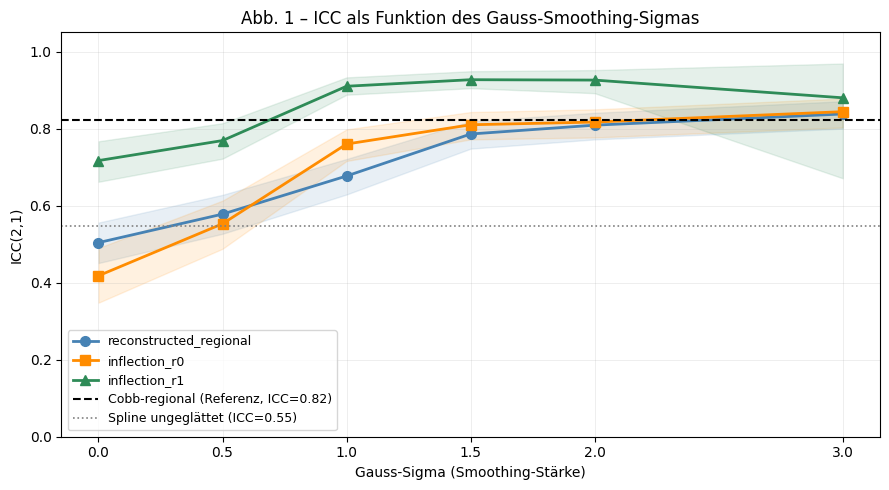

In [4]:
# Referenz-ICC aus dem Baseline-Datensatz (sigma=0, Cobb-regional)
angles_baseline = angles_by_sigma[0.0]
eligible_baseline = angles_baseline[angles_baseline['image_id'].isin(eligible_image_ids)]
icc_regional_ref = compute_icc(
    eligible_baseline[eligible_baseline['cobbType'] == 'Cobb-regional'],
    'image_id', 'rater_name', 'angle', min_images=10
)['ICC']
icc_spline_ref = compute_icc(
    eligible_baseline[eligible_baseline['cobbType'] == 'Spline'],
    'image_id', 'rater_name', 'angle', min_images=10
)['ICC']
print(f'Referenz Cobb-regional ICC: {icc_regional_ref:.3f}')
print(f'Referenz Spline ICC (ungeglättet): {icc_spline_ref:.3f}')

# Linienplot
colors = {'reconstructed_regional': 'steelblue', 'inflection_r0': 'darkorange', 'inflection_r1': 'seagreen'}
markers = {'reconstructed_regional': 'o', 'inflection_r0': 's', 'inflection_r1': '^'}

fig, ax = plt.subplots(figsize=(9, 5))
for cobb_type in TARGET_COBB_TYPES:
    sub = sweep_df[sweep_df['cobbType'] == cobb_type].sort_values('sigma')
    ax.plot(sub['sigma'], sub['ICC'],
            color=colors[cobb_type], marker=markers[cobb_type],
            label=cobb_type, linewidth=2, markersize=7)
    ax.fill_between(sub['sigma'], sub['CI95_lower'], sub['CI95_upper'],
                    color=colors[cobb_type], alpha=0.12)

ax.axhline(icc_regional_ref, color='black', linestyle='--', linewidth=1.5,
           label=f'Cobb-regional (Referenz, ICC={icc_regional_ref:.2f})')
ax.axhline(icc_spline_ref, color='gray', linestyle=':', linewidth=1.2,
           label=f'Spline ungeglättet (ICC={icc_spline_ref:.2f})')

ax.set_xlabel('Gauss-Sigma (Smoothing-Stärke)')
ax.set_ylabel('ICC(2,1)')
ax.set_ylim(0, 1.05)
ax.set_xticks(SIGMAS)
ax.set_title('Abb. 1 – ICC als Funktion des Gauss-Smoothing-Sigmas')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('output/smoothing_icc_vs_sigma.png', dpi=150)
plt.show()

---
## Schritt 3 – Optimales Sigma & Detailvergleich

In [6]:
# Optimales Sigma pro cobbType (maximaler ICC)
for cobb_type in TARGET_COBB_TYPES:
    sub = sweep_df[sweep_df['cobbType'] == cobb_type].dropna(subset=['ICC'])
    if len(sub) == 0:
        continue
    best = sub.loc[sub['ICC'].idxmax()]
    baseline = sub[sub['sigma'] == 0.0]['ICC'].values
    delta = best['ICC'] - (baseline[0] if len(baseline) else float('nan'))
    print(f'{cobb_type}: sigma_opt={best["sigma"]:.1f}, ICC={best["ICC"]:.3f} '
          f'(Δ={delta:+.3f} vs. sigma=0)')

# Zusammenfassungstabelle: alle Techniken bei sigma_opt vs. sigma=0
best_sigma_per_type = (
    sweep_df.loc[sweep_df.groupby('cobbType')['ICC'].idxmax()][['cobbType', 'sigma', 'ICC']]
    .set_index('cobbType')
    .rename(columns={'sigma': 'sigma_opt', 'ICC': 'ICC_smoothed'})
)
baseline_icc = (
    sweep_df[sweep_df['sigma'] == 0.0][['cobbType', 'ICC']]
    .set_index('cobbType')
    .rename(columns={'ICC': 'ICC_baseline'})
)
comparison_df = best_sigma_per_type.join(baseline_icc)
comparison_df['Delta_ICC'] = comparison_df['ICC_smoothed'] - comparison_df['ICC_baseline']

# Referenzzeilen anhängen
ref_rows = pd.DataFrame([
    {'sigma_opt': '-', 'ICC_smoothed': icc_regional_ref, 'ICC_baseline': icc_regional_ref, 'Delta_ICC': 0.0},
    {'sigma_opt': '-', 'ICC_smoothed': icc_spline_ref,   'ICC_baseline': icc_spline_ref,   'Delta_ICC': 0.0},
], index=['Cobb-regional (Referenz)', 'Spline (API, Referenz)'])
comparison_df = pd.concat([comparison_df, ref_rows])

print('\nTab. 1 – ICC Vergleich: baseline (sigma=0) vs. optimales Smoothing')
print(comparison_df.round(3).to_string())
comparison_df.to_csv('output/smoothing_icc_comparison.csv')

reconstructed_regional: sigma_opt=3.0, ICC=0.838 (Δ=+0.334 vs. sigma=0)
inflection_r0: sigma_opt=3.0, ICC=0.844 (Δ=+0.426 vs. sigma=0)
inflection_r1: sigma_opt=1.5, ICC=0.927 (Δ=+0.210 vs. sigma=0)

Tab. 1 – ICC Vergleich: baseline (sigma=0) vs. optimales Smoothing
                         sigma_opt  ICC_smoothed  ICC_baseline  Delta_ICC
inflection_r0                  3.0         0.844         0.418      0.426
inflection_r1                  1.5         0.927         0.717      0.210
reconstructed_regional         3.0         0.838         0.504      0.334
Cobb-regional (Referenz)         -         0.823         0.823      0.000
Spline (API, Referenz)           -         0.548         0.548      0.000


---
## Schritt 4 – Endpoint-Analyse

Der Haupttreiber der niedrigen Winkel-ICC ist laut `exp_Annotation_correctness.md` die
Variabilität der Endpunkt-Wahl. Hier messen wir direkt: wie stark verändern sich
die Node-Positionen am ersten und letzten Knoten durch das Smoothing?

Ø Verschiebung durch Smoothing (sigma=1.0) pro Positions-Gruppe:
                     mean   std  median
pos_group                              
first               16.64  4.57   16.93
inner                4.07  2.91    3.35
last                18.40  4.39   18.67
second/penultimate   6.15  3.69    5.50


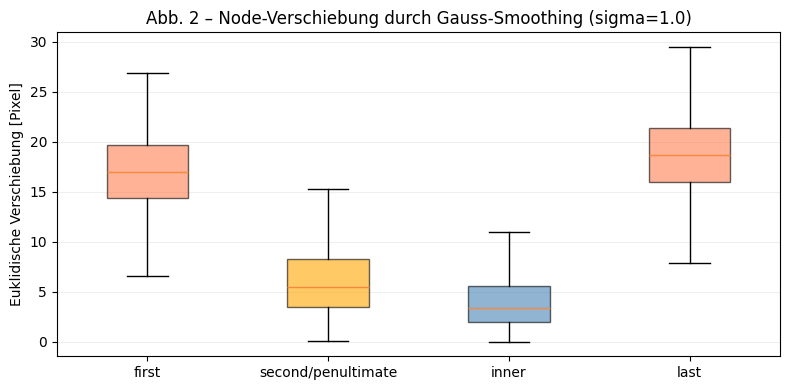

In [7]:
from bspline_python import smooth_nodes

# Für jede Messung: Node-Verschiebung durch Smoothing (sigma=1.0) pro Position
SIGMA_ANALYSIS = 1.0

shift_records = []
for _, row in df4d_corrected.iterrows():
    xmd = row['xray_measurement_data']
    if not isinstance(xmd, dict):
        continue
    nodes_raw = xmd.get('stateObject', {}).get('nodes', [])
    if len(nodes_raw) < 3:
        continue
    nodes_orig = [(n['x'], n['y']) for n in nodes_raw]
    nodes_smooth = smooth_nodes(nodes_orig, sigma=SIGMA_ANALYSIS)
    n = len(nodes_orig)
    for i, (orig, smooth) in enumerate(zip(nodes_orig, nodes_smooth)):
        dx = smooth[0] - orig[0]
        dy = smooth[1] - orig[1]
        dist = np.sqrt(dx**2 + dy**2)
        # Position als relative Index-Gruppe: first, last, inner
        if i == 0:
            pos_group = 'first'
        elif i == n - 1:
            pos_group = 'last'
        elif i in (1, n - 2):
            pos_group = 'second/penultimate'
        else:
            pos_group = 'inner'
        shift_records.append({
            'image_id': row['id'],
            'node_idx': i,
            'n_nodes': n,
            'pos_group': pos_group,
            'dx': dx, 'dy': dy, 'dist': dist
        })

shift_df = pd.DataFrame(shift_records)

print(f'Ø Verschiebung durch Smoothing (sigma={SIGMA_ANALYSIS}) pro Positions-Gruppe:')
summary_shift = shift_df.groupby('pos_group')['dist'].agg(['mean', 'std', 'median']).round(2)
print(summary_shift.to_string())

# Boxplot
order = ['first', 'second/penultimate', 'inner', 'last']
data_bp = [shift_df[shift_df['pos_group'] == g]['dist'].values for g in order]

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot(data_bp, labels=order, showfliers=False, patch_artist=True)
colors_bp = ['coral', 'orange', 'steelblue', 'coral']
for patch, col in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(col)
    patch.set_alpha(0.6)
ax.set_ylabel('Euklidische Verschiebung [Pixel]')
ax.set_title(f'Abb. 2 – Node-Verschiebung durch Gauss-Smoothing (sigma={SIGMA_ANALYSIS})')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/smoothing_node_shift_by_position.png', dpi=150)
plt.show()

---
## Schritt 5 – Korrelation mit Cobb-regional

Hypothese 2: Geglättete Spline-Winkel korrelieren stärker mit dem Goldstandard `Cobb-regional`.

Tab. 2 – Pearson r: reconstructed_regional vs. Cobb-regional als Funktion von sigma:
 sigma      r      p   n
   0.0 0.8953 0.0000 180
   0.5 0.9183 0.0000 188
   1.0 0.8882 0.0000 208
   1.5 0.8352 0.0000 205
   2.0 0.6700 0.0000 149
   3.0 0.2687 0.0174  78


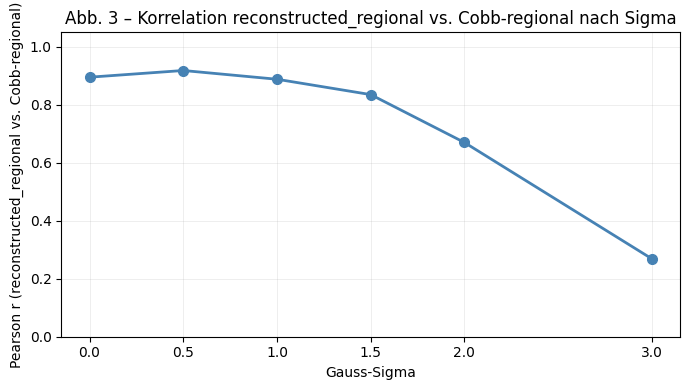

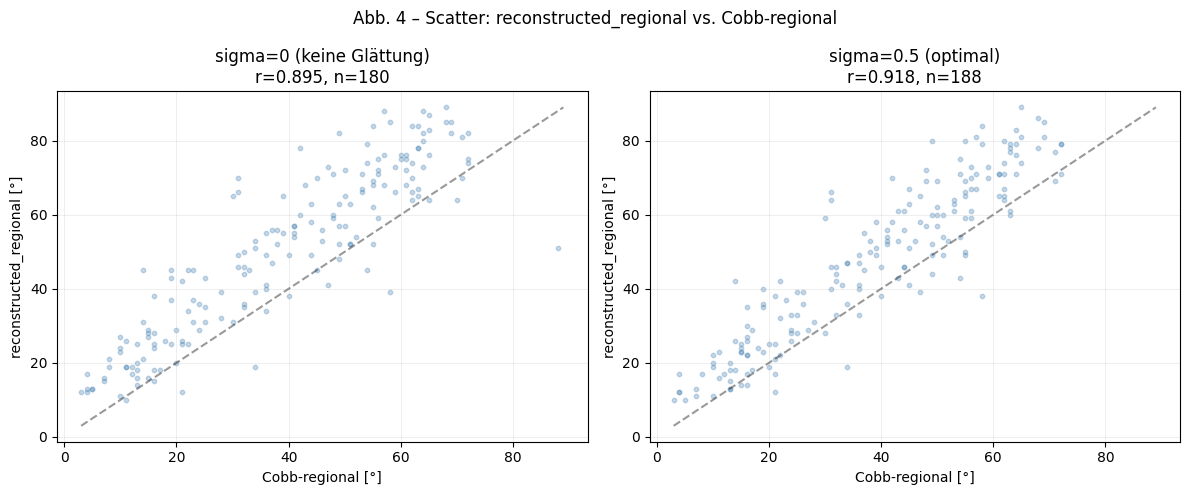

In [8]:
def match_angles_to_regional(angles_df, eligible_ids, cobb_type_a, cobb_type_b='Cobb-regional'):
    """Matche Winkelpaare nach (image_id, rater_name, vertebra_upper, vertebra_lower)."""
    elig = angles_df[angles_df['image_id'].isin(eligible_ids)]
    sub_a = elig[elig['cobbType'] == cobb_type_a][['image_id', 'rater_name', 'vertebra_upper', 'vertebra_lower', 'angle']]
    sub_b = elig[elig['cobbType'] == cobb_type_b][['image_id', 'rater_name', 'vertebra_upper', 'vertebra_lower', 'angle']]
    merged = sub_a.merge(sub_b, on=['image_id', 'rater_name', 'vertebra_upper', 'vertebra_lower'],
                         suffixes=('_a', '_b'))
    return merged.dropna(subset=['angle_a', 'angle_b'])

corr_records = []
for sigma in SIGMAS:
    df_s = angles_by_sigma[sigma]
    matched = match_angles_to_regional(df_s, eligible_image_ids, 'reconstructed_regional')
    if len(matched) >= 5:
        r, p = pearsonr(matched['angle_a'], matched['angle_b'])
        corr_records.append({'sigma': sigma, 'r': r, 'p': p, 'n': len(matched)})

corr_df = pd.DataFrame(corr_records)
print('Tab. 2 – Pearson r: reconstructed_regional vs. Cobb-regional als Funktion von sigma:')
print(corr_df.round(4).to_string(index=False))

# Linienplot r vs sigma
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(corr_df['sigma'], corr_df['r'], 'o-', color='steelblue', linewidth=2, markersize=7)
ax.set_xlabel('Gauss-Sigma')
ax.set_ylabel('Pearson r (reconstructed_regional vs. Cobb-regional)')
ax.set_xticks(SIGMAS)
ax.set_ylim(0, 1.05)
ax.set_title('Abb. 3 – Korrelation reconstructed_regional vs. Cobb-regional nach Sigma')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('output/smoothing_correlation_vs_sigma.png', dpi=150)
plt.show()

# Scatter: sigma=0 vs. sigma_opt
sigma_opt = corr_df.loc[corr_df['r'].idxmax(), 'sigma'] if len(corr_df) > 0 else 1.0
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, sig, title in zip(axes, [0.0, sigma_opt],
                          ['sigma=0 (keine Glättung)', f'sigma={sigma_opt} (optimal)']):
    matched = match_angles_to_regional(angles_by_sigma[sig], eligible_image_ids, 'reconstructed_regional')
    if len(matched) == 0:
        continue
    r_val, _ = pearsonr(matched['angle_a'], matched['angle_b'])
    ax.scatter(matched['angle_b'], matched['angle_a'], alpha=0.3, s=10, color='steelblue')
    lims = [min(matched[['angle_a', 'angle_b']].min()), max(matched[['angle_a', 'angle_b']].max())]
    ax.plot(lims, lims, 'k--', alpha=0.4)
    ax.set_xlabel('Cobb-regional [°]')
    ax.set_ylabel('reconstructed_regional [°]')
    ax.set_title(f'{title}\nr={r_val:.3f}, n={len(matched)}')
    ax.grid(alpha=0.3)
fig.suptitle('Abb. 4 – Scatter: reconstructed_regional vs. Cobb-regional', fontsize=12)
plt.tight_layout()
plt.savefig('output/smoothing_scatter_regional.png', dpi=150)
plt.show()

---
## Schritt 6 – Winkel-Std Reduktion über Rater

Direkter Test von Hypothese 1: Reduziert Smoothing die Inter-Rater-Std der Winkel?

Ø Inter-Rater-Std Cobb-regional (Referenz): 4.26°

Tab. 3 – Ø Inter-Rater-Std der Winkel als Funktion von sigma:
cobbType  inflection_r0  inflection_r1  reconstructed_regional
sigma                                                         
0.0               2.954          3.795                   4.476
0.5               2.507          3.440                   4.063
1.0               1.980          2.424                   2.728
1.5               1.600          1.569                   2.301
2.0               1.590          1.312                   2.061
3.0               1.039          0.695                   1.365


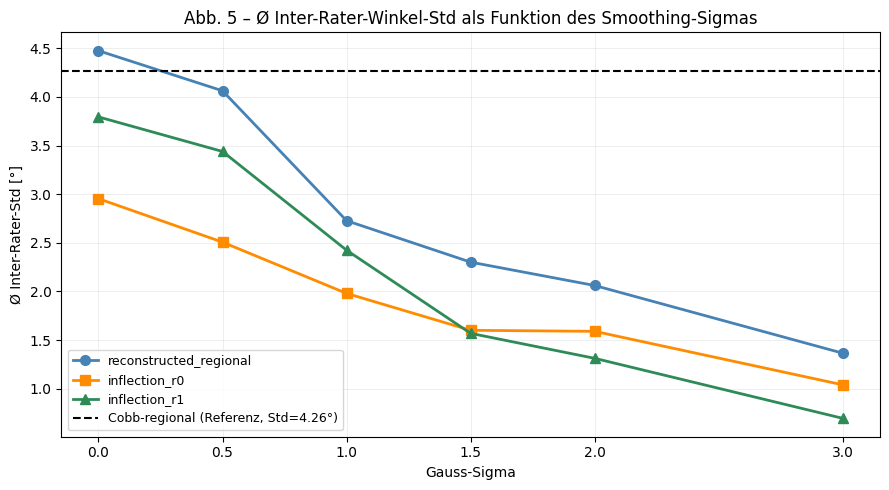

In [9]:
def compute_angle_std(angles_df, eligible_ids, cobb_type):
    """Ø Inter-Rater-Std der Winkel für einen cobbType (nur eligible Bilder, >=2 Rater)."""
    elig = angles_df[angles_df['image_id'].isin(eligible_ids)]
    sub = elig[elig['cobbType'] == cobb_type]
    within = (
        sub.groupby(['image_id', 'vertebra_upper', 'vertebra_lower'])['angle']
        .agg(['std', 'count'])
        .reset_index()
    )
    within = within[within['count'] >= 2]
    return within['std'].mean() if len(within) > 0 else float('nan')

std_records = []
for sigma in SIGMAS:
    df_s = angles_by_sigma[sigma]
    for cobb_type in TARGET_COBB_TYPES:
        std_val = compute_angle_std(df_s, eligible_image_ids, cobb_type)
        std_records.append({'sigma': sigma, 'cobbType': cobb_type, 'angle_std': std_val})

std_sweep_df = pd.DataFrame(std_records)

# Referenz-Std
std_cobb_regional = compute_angle_std(angles_by_sigma[0.0], eligible_image_ids, 'Cobb-regional')
print(f'Ø Inter-Rater-Std Cobb-regional (Referenz): {std_cobb_regional:.2f}°')

print('\nTab. 3 – Ø Inter-Rater-Std der Winkel als Funktion von sigma:')
print(std_sweep_df.pivot(index='sigma', columns='cobbType', values='angle_std').round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
for cobb_type in TARGET_COBB_TYPES:
    sub = std_sweep_df[std_sweep_df['cobbType'] == cobb_type].sort_values('sigma')
    ax.plot(sub['sigma'], sub['angle_std'],
            color=colors[cobb_type], marker=markers[cobb_type],
            label=cobb_type, linewidth=2, markersize=7)
ax.axhline(std_cobb_regional, color='black', linestyle='--', linewidth=1.5,
           label=f'Cobb-regional (Referenz, Std={std_cobb_regional:.2f}°)')
ax.set_xlabel('Gauss-Sigma')
ax.set_ylabel('Ø Inter-Rater-Std [°]')
ax.set_xticks(SIGMAS)
ax.set_title('Abb. 5 – Ø Inter-Rater-Winkel-Std als Funktion des Smoothing-Sigmas')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('output/smoothing_angle_std_vs_sigma.png', dpi=150)
plt.show()

---
## Schritt 7 – Ergebnis-Zusammenfassung

In [10]:
print('=== Ergebnis-Zusammenfassung: Regional Spline Smoothing ===')
print(f'MIN_INFLECTION_ANGLE = {MIN_INFLECTION_ANGLE}°')
print(f'Sigma-Sweep: {SIGMAS}')
print()

print('Tab. 4 – Vollständige Ergebnistabelle (ICC, Std, Korrelation mit Cobb-regional):')
summary_rows = []
for cobb_type in TARGET_COBB_TYPES:
    best_row = sweep_df[sweep_df['cobbType'] == cobb_type].loc[
        sweep_df[sweep_df['cobbType'] == cobb_type]['ICC'].idxmax()
    ]
    base_icc = sweep_df[
        (sweep_df['cobbType'] == cobb_type) & (sweep_df['sigma'] == 0.0)
    ]['ICC'].values
    base_std = std_sweep_df[
        (std_sweep_df['cobbType'] == cobb_type) & (std_sweep_df['sigma'] == 0.0)
    ]['angle_std'].values
    best_std = std_sweep_df[
        (std_sweep_df['cobbType'] == cobb_type) & (std_sweep_df['sigma'] == best_row['sigma'])
    ]['angle_std'].values
    summary_rows.append({
        'cobbType':      cobb_type,
        'sigma_opt':     best_row['sigma'],
        'ICC_baseline':  round(base_icc[0], 3) if len(base_icc) else float('nan'),
        'ICC_smoothed':  round(best_row['ICC'], 3),
        'Delta_ICC':     round(best_row['ICC'] - (base_icc[0] if len(base_icc) else float('nan')), 3),
        'Std_baseline':  round(base_std[0], 2) if len(base_std) else float('nan'),
        'Std_smoothed':  round(best_std[0], 2) if len(best_std) else float('nan'),
    })

# Referenzzeilen
summary_rows.append({
    'cobbType': 'Cobb-regional (Referenz)',
    'sigma_opt': '-', 'ICC_baseline': round(icc_regional_ref, 3), 'ICC_smoothed': round(icc_regional_ref, 3),
    'Delta_ICC': 0.0,
    'Std_baseline': round(std_cobb_regional, 2), 'Std_smoothed': round(std_cobb_regional, 2),
})
summary_rows.append({
    'cobbType': 'Spline (API, ungeglättet)',
    'sigma_opt': '-', 'ICC_baseline': round(icc_spline_ref, 3), 'ICC_smoothed': round(icc_spline_ref, 3),
    'Delta_ICC': 0.0,
    'Std_baseline': round(compute_angle_std(angles_by_sigma[0.0], eligible_image_ids, 'Spline'), 2),
    'Std_smoothed': float('nan'),
})

summary_final = pd.DataFrame(summary_rows).set_index('cobbType')
print(summary_final.to_string())
summary_final.to_csv('output/smoothing_summary.csv')

print()
print('Hypothesen-Check:')
h1 = any(r['Delta_ICC'] > 0 for r in summary_rows[:3])
h3 = any(r['Std_smoothed'] < r['Std_baseline'] for r in summary_rows[:3] if not np.isnan(r.get('Std_smoothed', float('nan'))))
print(f'  H1 (Std-Reduktion durch Smoothing):       {"bestätigt" if h3 else "nicht bestätigt"}')
print(f'  H3 (ICC-Verbesserung durch Smoothing):    {"bestätigt" if h1 else "nicht bestätigt"}')
print(f'  Korrelation mit Cobb-regional (sigma=0):  r={corr_df[corr_df["sigma"]==0.0]["r"].values[0]:.3f}')
if len(corr_df) > 1:
    best_r_row = corr_df.loc[corr_df['r'].idxmax()]
    print(f'  Korrelation mit Cobb-regional (optimal):  r={best_r_row["r"]:.3f} (sigma={best_r_row["sigma"]})')

=== Ergebnis-Zusammenfassung: Regional Spline Smoothing ===
MIN_INFLECTION_ANGLE = 10.0°
Sigma-Sweep: [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]

Tab. 4 – Vollständige Ergebnistabelle (ICC, Std, Korrelation mit Cobb-regional):
                          sigma_opt  ICC_baseline  ICC_smoothed  Delta_ICC  Std_baseline  Std_smoothed
cobbType                                                                                              
reconstructed_regional          3.0         0.504         0.838      0.334          4.48          1.36
inflection_r0                   3.0         0.418         0.844      0.426          2.95          1.04
inflection_r1                   1.5         0.717         0.927      0.210          3.79          1.57
Cobb-regional (Referenz)          -         0.823         0.823      0.000          4.26          4.26
Spline (API, ungeglättet)         -         0.548         0.548      0.000          3.34           NaN

Hypothesen-Check:
  H1 (Std-Reduktion durch Smoothing):       b